# 11 · Reinforcement learning basics

MDPs on grid worlds: solve them with value and policy iteration when the model is known, learn them with
Q-learning and SARSA when it is not — all in C++, inspected from Python.

In [1]:
# Installs the module when it is missing (e.g. on Colab); a local `pip install -e .` is used as is.
import importlib.util

if importlib.util.find_spec("motion_planning") is None:
    %pip install -q git+https://github.com/Rudip1/learn-motion-planning

## Recap

Theory: [`1_theory/11_reinforcement_learning.md`](../../1_theory/11_reinforcement_learning.md).

- MDP $\langle S, A, P, R, \gamma \rangle$ (11.1); return $G_t = \sum_k \gamma^k r_{t+k+1}$ (11.2).
- Policy evaluation is linear: $(I - \gamma P_\pi) V^\pi = r_\pi$ (11.3); $Q(s, a)$ from $V$ (11.4); greedy policy
  (11.5).
- Value iteration $V_{k+1} = \max_a Q_k$ (11.6) is a $\gamma$-contraction (11.7); policy iteration alternates exact
  evaluation and greedy improvement.
- TD control: $Q \leftarrow Q + \alpha(\text{target} - Q)$ (11.8); Q-learning bootstraps on $\max_{a'} Q(s', a')$,
  SARSA on the action actually taken (11.9); ε-greedy exploration (11.10).

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from motion_planning import rl
from motion_planning.plotting import INK, SERIES, use_style

use_style()
ROOM = ["S....#....",
        ".##..#.##.",
        ".#.......G",
        ".#..###...",
        "....#....."]
ARROWS = "↑→↓←"


def show(grid, V=None, policy=None, title=""):
    """Print a grid with optimal values or policy arrows."""
    print(title)
    for r in range(grid.rows):
        cells = []
        for c in range(grid.cols):
            s = grid.state(r, c)
            ch = grid.cell(s)
            if ch in "#GP":
                cells.append(f"{ch:>6}")
            elif policy is not None:
                cells.append(f"{ARROWS[policy[s]]:>6}")
            else:
                cells.append(f"{V[s]:6.1f}")
        print("".join(cells))

## Value iteration on a room

Every move costs 1; the goal is 11 moves from the start.

V* (gamma = 1), 14 sweeps
 -11.0 -10.0  -9.0  -8.0  -7.0     #  -5.0  -4.0  -3.0  -2.0
 -12.0     #     #  -7.0  -6.0     #  -4.0     #     #  -1.0
 -13.0     #  -7.0  -6.0  -5.0  -4.0  -3.0  -2.0  -1.0     G
 -12.0     #  -8.0  -7.0     #     #     #  -3.0  -2.0  -1.0
 -11.0 -10.0  -9.0  -8.0     #  -6.0  -5.0  -4.0  -3.0  -2.0

greedy policy
     →     →     →     →     ↓     #     →     →     →     ↓
     ↑     #     #     →     ↓     #     ↓     #     #     ↓
     ↑     #     →     →     →     →     →     →     →     G
     ↓     #     ↑     ↑     #     #     #     ↑     ↑     ↑
     →     →     ↑     ↑     #     →     →     ↑     ↑     ↑


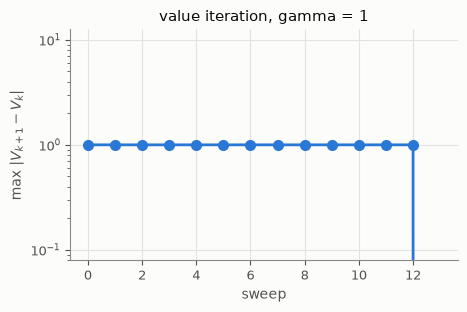

In [3]:
room = rl.GridWorld.from_layout(ROOM)
m = room.to_mdp()
vi = rl.value_iteration(m, 1.0)
show(room, V=vi.V, title=f"V* (gamma = 1), {vi.iterations} sweeps")
show(room, policy=vi.policy, title="\ngreedy policy")
plt.figure(figsize=(5, 3))
plt.semilogy(vi.residuals, "o-")
plt.xlabel("sweep"); plt.ylabel(r"max $|V_{k+1} - V_k|$"); plt.title("value iteration, gamma = 1"); plt.show()

### ✏️ Exercise 1 — one Bellman backup

Implement eq. (11.4) and one sweep of eq. (11.6) in NumPy, using `m.P[s][a]` (a list of transitions with
`next`, `probability`, `reward`). Terminal states keep the value 0.

In [4]:
def q_value(m, V, s, a, gamma):
    return sum(t.probability * (t.reward + gamma * V[t.next]) for t in m.P[s][a])


def bellman_sweep(m, V, gamma):
    out = np.zeros_like(V)
    for s in range(m.num_states):
        if not m.is_terminal(s):
            out[s] = max(q_value(m, V, s, a, gamma) for a in range(m.num_actions))
    return out

In [5]:
slippery = rl.GridWorld.from_layout(ROOM, -1.0, 10.0, -100.0, 0.2).to_mdp()
V = np.zeros(slippery.num_states)
for _ in range(400):
    V = bellman_sweep(slippery, V, 0.95)
assert np.allclose(V, rl.value_iteration(slippery, 0.95, 1e-12).V, atol=1e-8)
print("✓ bellman_sweep")

✓ bellman_sweep


### ✏️ Exercise 2 — values from distances

In the deterministic room, compute $V^*$ for $\gamma = 0.9$ from breadth-first distances to the goal with eq.
(11.11), without any MDP code, and compare.

In [6]:
from collections import deque


def distances(grid):
    d = {s: None for s in range(grid.rows * grid.cols)}
    q = deque(s for s in d if grid.cell(s) == "G")
    for s in q:
        d[s] = 0
    while q:
        s = q.popleft()
        for dr, dc in ((-1, 0), (0, 1), (1, 0), (0, -1)):
            r, c = grid.row(s) + dr, grid.col(s) + dc
            if 0 <= r < grid.rows and 0 <= c < grid.cols and grid.layout[r][c] != "#":
                n = grid.state(r, c)
                if d[n] is None:
                    d[n] = d[s] + 1
                    q.append(n)
    return d


def v_from_distance(dist, gamma):
    return -(1 - gamma ** dist) / (1 - gamma)

In [7]:
d = distances(room)
V09 = rl.value_iteration(m, 0.9, 1e-12).V
for s in range(m.num_states):
    if not m.is_terminal(s):
        assert abs(V09[s] - v_from_distance(d[s], 0.9)) < 1e-9
print("✓ V* = -(1 - gamma^d) / (1 - gamma), e.g. start:", round(V09[room.start()], 3))

✓ V* = -(1 - gamma^d) / (1 - gamma), e.g. start: -6.862


## Policy iteration

Exact evaluation (11.3) and greedy improvement. Few iterations, each a linear solve.

In [8]:
pi = rl.policy_iteration(slippery, 0.95)
vi_s = rl.value_iteration(slippery, 0.95, 1e-12)
print(f"policy iteration: {pi.iterations} steps; value iteration: {vi_s.iterations} sweeps; "
      f"max |V_pi - V_vi| = {np.abs(pi.V - vi_s.V).max():.1e}")

policy iteration: 6 steps; value iteration: 65 sweeps; max |V_pi - V_vi| = 8.3e-13


### ✏️ Exercise 3 — policy evaluation as a linear system

Build $I - \gamma P_\pi$ and $r_\pi$ for a policy and solve (11.3) with `np.linalg.solve`. Terminal rows are the
identity with right-hand side 0.

In [9]:
def evaluate(m, policy, gamma):
    n = m.num_states
    A, b = np.eye(n), np.zeros(n)
    for s in range(n):
        if m.is_terminal(s):
            continue
        for t in m.P[s][policy[s]]:
            A[s, t.next] -= gamma * t.probability
            b[s] += t.probability * t.reward
    return np.linalg.solve(A, b)

In [10]:
policy = [max(a, 0) for a in pi.policy]
assert np.allclose(evaluate(slippery, policy, 0.95), rl.evaluate_policy(slippery, policy, 0.95))
print("✓ evaluate")

✓ evaluate


## How much caution does slip deserve?

The cliff with slip 0, 0.1, 0.2: the optimal policy moves away from the edge, and at slip 0.2 the start action is
to push into the wall (←): it waits for a safe drift upwards.

In [11]:
cliff = rl.cliff_world()
for slip in (0.0, 0.1, 0.2):
    g = rl.GridWorld.from_layout(cliff.layout, -1.0, 0.0, -100.0, slip)
    v = rl.value_iteration(g.to_mdp(), 1.0, 1e-10)
    show(g, policy=v.policy, title=f"\nslip {slip}: V*(start) = {v.V[g.start()]:.1f}")


slip 0.0: V*(start) = -13.0
     →     →     →     →     →     →     →     →     →     →     →     ↓
     →     →     →     →     →     →     →     →     →     →     →     ↓
     →     →     →     →     →     →     →     →     →     →     →     ↓
     ↑     P     P     P     P     P     P     P     P     P     P     G

slip 0.1: V*(start) = -22.1
     →     →     →     →     →     →     →     →     →     →     →     ↓
     →     →     →     →     →     →     →     →     →     →     →     ↓
     ↑     ↑     ↑     ↑     ↑     ↑     ↑     ↑     ↑     ↑     ↑     ↓
     ↑     P     P     P     P     P     P     P     P     P     P     G

slip 0.2: V*(start) = -29.8
     →     →     →     →     →     →     →     →     →     →     →     ↓
     →     →     →     →     →     →     →     →     →     →     →     ↓
     ↑     ↑     ↑     ↑     ↑     ↑     ↑     ↑     ↑     ↑     ↑     ↓
     ←     P     P     P     P     P     P     P     P     P     P     G


## Learning: Q-learning against SARSA

The agent does not see $P$: it acts, observes, updates. Same cliff, ε = 0.1.

Q-learning mean return of the last 100 episodes -39.0, falls 139
SARSA      mean return of the last 100 episodes -23.8, falls 40


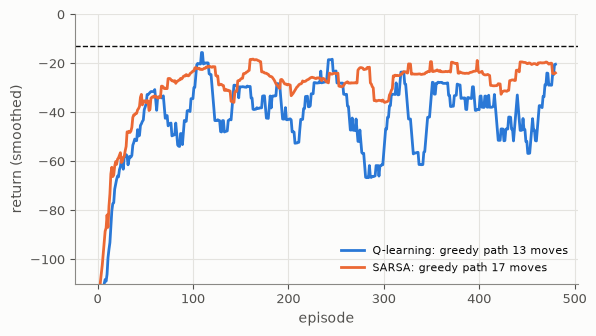

In [12]:
cm = cliff.to_mdp()
fig, ax = plt.subplots(figsize=(6.5, 3.5))
for k, (name, method) in enumerate([("Q-learning", rl.TdMethod.QLearning), ("SARSA", rl.TdMethod.Sarsa)]):
    r = rl.td_control(cm, cliff.start(), rl.TdConfig(method, 1.0, 0.5, 0.1, 500, 1000, 7))
    path = rl.rollout(cm, rl.greedy_from_q(cm, r.Q), cliff.start())
    smooth = np.convolve(r.episode_returns, np.ones(20) / 20, mode="valid")
    ax.plot(smooth, color=SERIES[k], label=f"{name}: greedy path {len(path) - 1} moves")
    print(f"{name:10s} mean return of the last 100 episodes {np.mean(r.episode_returns[-100:]):.1f}, "
          f"falls {sum(x <= -100 for x in r.episode_returns)}")
ax.axhline(-13, color=INK, ls="--", lw=1)
ax.set_ylim(-110, 0); ax.set_xlabel("episode"); ax.set_ylabel("return (smoothed)"); ax.legend(fontsize=8)
plt.show()

### ✏️ Exercise 4 — the Q-learning update

Write tabular Q-learning yourself (eqs. 11.8–11.10) for the room, using `rl.Simulator`-like sampling from
`m.P` with NumPy's random generator. After 300 episodes its greedy policy must reach the goal in 11 moves.

In [13]:
def q_learning(m, start, episodes=300, alpha=0.5, epsilon=0.2, gamma=1.0, seed=0):
    rng = np.random.default_rng(seed)
    Q = np.zeros((m.num_states, m.num_actions))

    def act(s):
        if rng.random() < epsilon:
            return int(rng.integers(m.num_actions))
        best = np.flatnonzero(Q[s] == Q[s].max())
        return int(rng.choice(best))

    for _ in range(episodes):
        s = start
        for _ in range(1000):
            a = act(s)
            outcomes = m.P[s][a]
            t = outcomes[rng.choice(len(outcomes), p=[o.probability for o in outcomes])]
            target = t.reward if m.is_terminal(t.next) else t.reward + gamma * Q[t.next].max()
            Q[s, a] += alpha * (target - Q[s, a])
            if m.is_terminal(t.next):
                break
            s = t.next
    return Q

In [14]:
Q = q_learning(m, room.start())
path = rl.rollout(m, rl.greedy_from_q(m, Q), room.start())
assert len(path) - 1 == 11 and room.cell(path[-1]) == "G"
print("✓ q_learning: greedy path", len(path) - 1, "moves")

✓ q_learning: greedy path 11 moves


## 🔨 Break it — what exploration costs

Train Q-learning on the cliff with ε = 0, 0.1 and 0.3. Surprise: ε = 0 still finds the optimal path. $Q$ starts
at 0 and every reward is negative, so an action that has been tried looks *worse* than one that has not, and the
greedy agent tries everything — **optimistic initial values** do the exploring. Raising ε only adds falls.

In [15]:
for eps in (0.0, 0.1, 0.3):
    r = rl.td_control(cm, cliff.start(), rl.TdConfig(rl.TdMethod.QLearning, 1.0, 0.5, eps, 500, 1000, 7))
    path = rl.rollout(cm, rl.greedy_from_q(cm, r.Q), cliff.start())
    print(f"epsilon {eps}: falls {sum(x <= -100 for x in r.episode_returns):3d} / 500, "
          f"greedy path {len(path) - 1} moves, mean return of the last 100 episodes {np.mean(r.episode_returns[-100:]):.1f}")

epsilon 0.0: falls  11 / 500, greedy path 13 moves, mean return of the last 100 episodes -13.0
epsilon 0.1: falls 139 / 500, greedy path 13 moves, mean return of the last 100 episodes -39.0
epsilon 0.3: falls 303 / 500, greedy path 13 moves, mean return of the last 100 episodes -72.5


## 🔨 Break it — gamma = 1 and a policy that never ends

Evaluate "always push up" in the room with $\gamma = 1$: from the top row the agent bumps into the border forever,
so its return is $-\infty$ and the linear system (11.3) is singular.

In [16]:
always_up = [0] * m.num_states
try:
    rl.evaluate_policy(m, always_up, 1.0)
except RuntimeError as e:
    print("RuntimeError:", e)
print("with gamma = 0.9 it is finite:", round(rl.evaluate_policy(m, always_up, 0.9)[room.start()], 2), "= -1 / (1 - 0.9)")

RuntimeError: evaluate_policy: the policy never terminates from some state (use gamma < 1)
with gamma = 0.9 it is finite: -10.0 = -1 / (1 - 0.9)


## 🔨 Break it — a learning rate that never settles

With slip, transitions are random and a constant α keeps $Q$ jumping around its target. Compare the spread of
$\max_a Q(\text{start}, a)$ over the last 200 of 2000 episodes for α = 0.5 and α = 0.05 with the true $V^*$.

In [17]:
g02 = rl.GridWorld.from_layout(ROOM, -1.0, 0.0, -100.0, 0.2)
m02 = g02.to_mdp()
v_star = rl.value_iteration(m02, 1.0, 1e-10).V[g02.start()]
for alpha in (0.5, 0.05):
    vals = []
    for seed in range(1, 6):
        r = rl.td_control(m02, g02.start(), rl.TdConfig(rl.TdMethod.QLearning, 1.0, alpha, 0.2, 2000, 1000, seed))
        vals.append(r.Q[g02.start()].max())
    print(f"alpha {alpha}: max Q(start) over 5 seeds = {np.round(vals, 2)}  (V* = {v_star:.2f})")

alpha 0.5: max Q(start) over 5 seeds = [-13.88 -16.33 -13.92 -13.84 -12.47]  (V* = -14.67)
alpha 0.05: max Q(start) over 5 seeds = [-14.73 -14.08 -14.64 -14.69 -14.46]  (V* = -14.67)


## What to remember

- An MDP adds probabilities to planning; the optimal policy trades speed against risk (the cliff with slip).
- Value iteration is a $\gamma$-contraction; policy iteration converges in few exact steps.
- Q-learning learns the optimal policy off-policy; SARSA learns the value of what it actually does, exploration
  included — safer while learning.
- Exploration is necessary, and costs: learn in simulation before trusting a robot near a cliff.